# `swing-analyzer` 0.1.2 benchmark

Executed against the golftracker project's `00001.mov` and `00002.mov` samples. This notebook uses the published wheel and its public Python functions; it does not implement another pose estimator. The sample clips are down-the-line, so face-on rotation metrics are deliberately treated as unreliable.

Status: package import and pose analysis work. The package's native `avc1` writer fails on this Linux host and the package does not check `VideoWriter.isOpened()`. The failure is probed below, followed by a runtime-only `mp4v` codec fallback; site-packages are not modified.

In [1]:
from pathlib import Path
import ast, inspect, json, platform, sys, traceback
import importlib.metadata as md
import cv2, matplotlib.pyplot as plt, numpy as np, pandas as pd
from IPython.display import display, Markdown, Video

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
SAMPLES = ROOT / "data" / "raw" / "golftracker_samples"
OUT = ROOT / "outputs" / "swing_analyzer"
OUT.mkdir(parents=True, exist_ok=True)

from swing_analyzer import analyze
import swing_analyzer.compare as compare_mod

versions = pd.DataFrame({"value": {
    "Python": platform.python_version(),
    "swing-analyzer": md.version("swing-analyzer"),
    "MediaPipe": md.version("mediapipe"),
    "OpenCV": cv2.__version__,
    "NumPy": np.__version__,
    "SciPy": md.version("scipy"),
}})
display(versions)
print("import path:", inspect.getfile(analyze))
print("Requires-Python:", md.metadata("swing-analyzer").get("Requires-Python"))
print("Declared requirements:", md.requires("swing-analyzer"))

,value
Python,3.11.18
swing-analyzer,0.1.2
MediaPipe,0.10.14
OpenCV,5.0.0
NumPy,2.4.6
SciPy,1.17.1


import path: /home/tsispace/Documents/GitHub/golf-balance/envs/swing-analyzer/lib/python3.11/site-packages/swing_analyzer/analyze.py
Requires-Python: <3.13,>=3.9
Declared requirements: ['mediapipe==0.10.14', 'opencv-python', 'numpy', 'scipy']


## Installed source structure and algorithms

Important source locations in 0.1.2:

- `analyze.py`: `analyze_video` (line 183), `detect_phases` (431), `summarize_metrics` (609), retiming/framing/report helpers.
- `core.py`: drawing geometry and `PoseTracker`, which wraps legacy `mediapipe.solutions.pose.Pose` with complexity 1, detection confidence 0.5, tracking confidence 0.5.
- `compare.py`: runs the analyzer twice, phase-warps videos, and diffs only the summary dictionaries.
- `full.py`: coaching-style fault rules and two-view reporting.

The analyzer retains only selected derived frame fields—not all 33 landmarks and not landmark visibility. Metrics use raw landmark positions; the skeleton drawing is EMA-smoothed (`POSE_EMA=0.5`), the wrist tracer uses an EMA (`0.6`) plus a five-point moving-average polyline, and phase detection smooths wrist height with a three-frame box filter.

In [2]:
package_dir = Path(inspect.getfile(analyze)).parent
rows = []
for path in sorted(package_dir.glob("*.py")):
    tree = ast.parse(path.read_text())
    defs = [f"{n.name}:{n.lineno}" for n in tree.body if isinstance(n, (ast.FunctionDef, ast.ClassDef))]
    rows.append({"file": path.name, "lines": len(path.read_text().splitlines()), "top-level definitions": ", ".join(defs)})
display(pd.DataFrame(rows))

,file,lines,top-level definitions
0,__init__.py,0,
1,analyze.py,1338,"_smooth_points:137, face_box:152, apply_mosaic..."
2,cli.py,43,main:14
3,compare.py,196,"_source_dims:30, _bake_specs:38, compare:57, w..."
4,core.py,163,"FrameMetrics:43, get_pixel:54, angle_from_vert..."
5,full.py,634,"_severity:55, assess:63, combine_views:415, _t..."
6,report_html.py,596,"_frames:74, _photo:88, _head:108, _golfer:116,..."
7,scroll_html.py,380,"_video_data_uri:24, _fault_card:29, build_scro..."


## Native output-codec failure, then documented fallback

`VIDEO_FOURCC` is hard-coded to `avc1`. OpenCV can read the input but this host has no usable H.264 encoder. The package writes no file and raises no exception because it never checks whether the writer opened.

In [3]:
probe_path = OUT / "codec_probe.mp4"
probe = cv2.VideoWriter(str(probe_path), cv2.VideoWriter_fourcc(*analyze.VIDEO_FOURCC), 30, (432, 768))
native_codec_opened = probe.isOpened()
probe.release()
if probe_path.exists():
    probe_path.unlink()
print({"package_codec": analyze.VIDEO_FOURCC, "VideoWriter.isOpened": native_codec_opened})

# Runtime-only fallback; the installed package remains untouched.
analyze.OUTPUT_DIR = str(OUT)
compare_mod.OUTPUT_DIR = str(OUT)
analyze.VIDEO_FOURCC = "mp4v"
video_a = SAMPLES / "00001.mov"
out_path, frames_data, fps = analyze.analyze_video(str(video_a), view_type="dtl")
phases = analyze.detect_phases(frames_data, fps)
summary = analyze.summarize_metrics(frames_data, phases)
flags = analyze.flag_issues(summary, view_type="dtl")
print("annotated output:", out_path, Path(out_path).exists(), Path(out_path).stat().st_size)
print("frames / tracked frames / fps:", len(frames_data), sum("wrist_x" in x for x in frames_data), fps)
display(pd.Series(phases, name="frame").to_frame())
display(pd.Series(summary, name="value").to_frame())
print(*flags, sep="\n")

{'package_codec': 'avc1', 'VideoWriter.isOpened': False}


[h264_v4l2m2m @ 0x55ea2b7850c0] Could not find a valid device
[h264_v4l2m2m @ 0x55ea2b7850c0] can't configure encoder
[ERROR:0@0.849] global cap_ffmpeg_impl.hpp:3568 open Could not open codec h264_v4l2m2m, error: Unspecified error (-22)
[ERROR:0@0.849] global cap_ffmpeg_impl.hpp:3585 open VIDEOIO/FFMPEG: Failed to initialize VideoWriter
I0000 00:00:1793674444.693654   29749 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674444.697333   29840 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1793674444.749657   29819 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674444.766855   29823 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support fo

annotated output: /home/tsispace/Documents/GitHub/golf-balance/outputs/swing_analyzer/annotated_00001.mp4 True 1999975
frames / tracked frames / fps: 136 136 30.0


,frame
address_frame,0
backswing_start_frame,46
top_of_backswing_frame,80
impact_frame,89
release_frame,93
finish_frame,135


,value
spine_angle_address,33.840056
spine_angle_impact,33.048125
spine_angle_delta,-0.791931
shoulder_turn,6.139818
hip_turn,NaN
head_sway,0.034307
head_vertical,0.045624
arm_collapse_top,145.953134
reverse_spine,0.043125
chicken_wing,25.190250


✅ **Spine angle at address**: 33.8 — within normal range
— **Shoulder / hip turn at top**: not measurable from this camera angle (rotation is toward/away from the lens, so the projected angle carries little of it) — filmed face-on to read
✅ **Head sway (address -> top)**: 0.0 — within normal range
✅ **Spine angle change (address→impact)**: -0.8° — well maintained


## What the events actually mean

- **Address** is the first frame with a detected pose, not a learned or biomechanical address detector.
- **Top** is the first prominent minimum of smoothed wrist `y` (hands high), with a threshold/plateau fallback.
- **Impact** is the first prominent wrist-`y` maximum after top (hands low), with velocity/return-height fallbacks. There is no ball contact observation.
- **Release** is fixed at about 0.12 seconds after estimated impact.
- **Finish** is the last tracked frame, not a finish-pose detector.

Thus frame numbers are reproducible heuristic events, not ground-truth impact labels. The swing-plane overlay is a fixed line through the address hands at a default 54° shaft angle; it is not a detected shaft or club path.

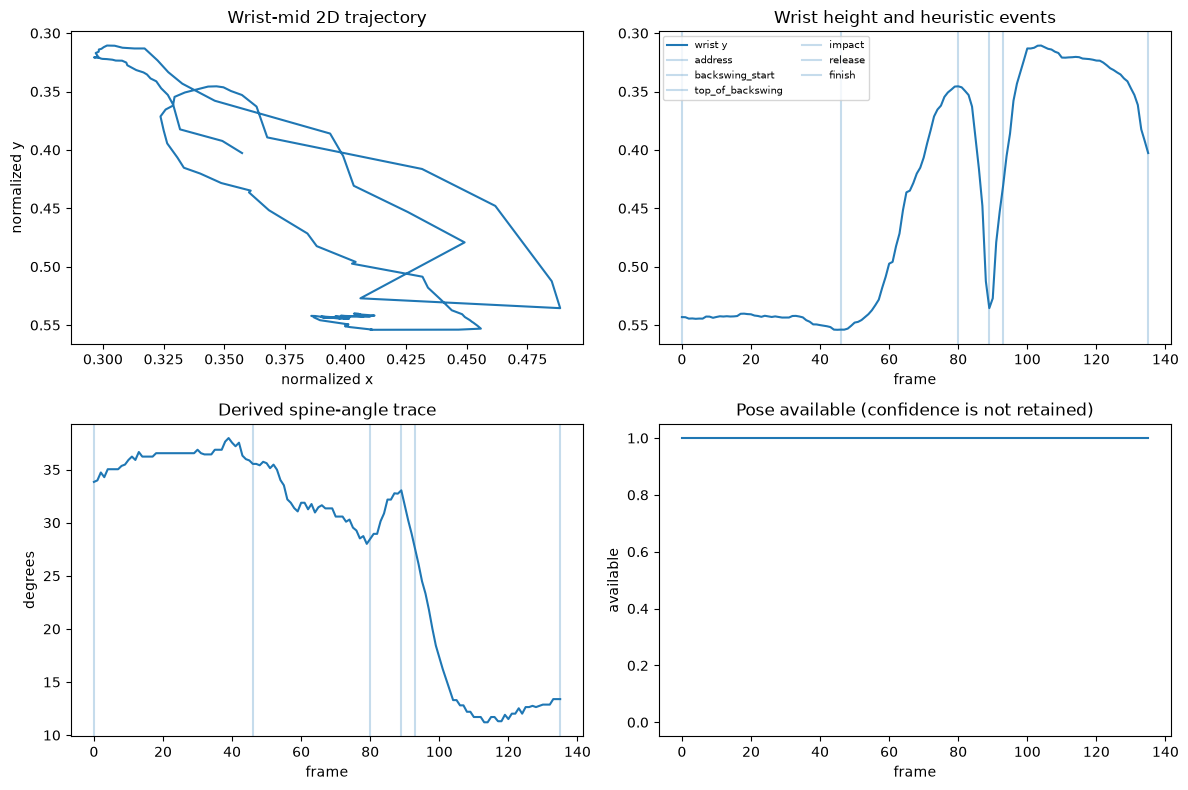

In [4]:
scalar_rows = [{k: v for k, v in row.items() if not isinstance(v, tuple)} for row in frames_data]
frame_df = pd.DataFrame(scalar_rows)
frame_df.to_csv(OUT / "00001_frame_metrics.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0,0].plot(frame_df.wrist_x, frame_df.wrist_y)
axes[0,0].invert_yaxis(); axes[0,0].set(title="Wrist-mid 2D trajectory", xlabel="normalized x", ylabel="normalized y")
axes[0,1].plot(frame_df.frame, frame_df.wrist_y, label="wrist y")
axes[1,0].plot(frame_df.frame, frame_df.spine_angle, label="spine angle")
axes[1,1].plot(frame_df.frame, frame_df.wrist_x.notna().astype(int)); axes[1,1].set_ylim(-0.05, 1.05)
axes[1,1].set(title="Pose available (confidence is not retained)", xlabel="frame", ylabel="available")
for ax in (axes[0,1], axes[1,0]):
    for label, frame in phases.items():
        ax.axvline(frame, alpha=.25, label=label.replace("_frame", ""))
axes[0,1].invert_yaxis(); axes[0,1].set(title="Wrist height and heuristic events", xlabel="frame")
axes[1,0].set(title="Derived spine-angle trace", xlabel="frame", ylabel="degrees")
axes[0,1].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(OUT / "00001_diagnostics.png", dpi=140)
plt.show()

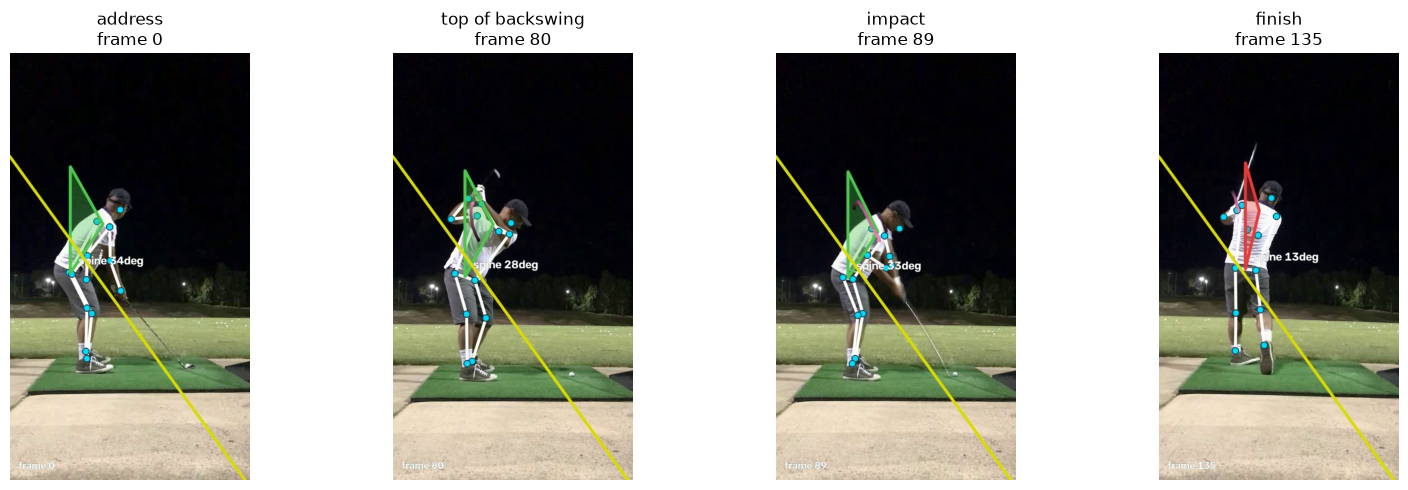

In [5]:
cap = cv2.VideoCapture(str(out_path))
key_names = ["address_frame", "top_of_backswing_frame", "impact_frame", "finish_frame"]
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, name in zip(axes, key_names):
    idx = phases[name]
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
    ok, frame = cap.read()
    if ok:
        ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name.replace('_frame','').replace('_',' ')}\nframe {idx}")
    ax.axis("off")
cap.release(); fig.tight_layout(); fig.savefig(OUT / "00001_key_frames.png", dpi=140)
plt.show()

## Genuine measurements versus instructional heuristics

In [6]:
classification = pd.DataFrame([
    ("wrist/head/joint normalized coordinates", "MediaPipe-derived measurement", "2D image coordinates; selected points only"),
    ("spine and projected shoulder/hip line angles", "derived geometry", "projection-sensitive; not 3D rotation"),
    ("head sway / head vertical / ankle change", "derived geometry", "normalized image displacement"),
    ("top and impact frames", "signal heuristic", "wrist-height peaks/fallbacks; no club or ball evidence"),
    ("address and finish frames", "clip-boundary heuristic", "first and last tracked frames"),
    ("swing-plane line", "instructional proxy", "hands anchor plus default/manual shaft angle"),
    ("TARGETS and flags", "coaching heuristic", "hard-coded generic ranges, not validated personal norms"),
], columns=["output", "type", "interpretation"])
display(classification)

,output,type,interpretation
0,wrist/head/joint normalized coordinates,MediaPipe-derived measurement,2D image coordinates; selected points only
1,spine and projected shoulder/hip line angles,derived geometry,projection-sensitive; not 3D rotation
2,head sway / head vertical / ankle change,derived geometry,normalized image displacement
3,top and impact frames,signal heuristic,wrist-height peaks/fallbacks; no club or ball ...
4,address and finish frames,clip-boundary heuristic,first and last tracked frames
5,swing-plane line,instructional proxy,hands anchor plus default/manual shaft angle
6,TARGETS and flags,coaching heuristic,"hard-coded generic ranges, not validated perso..."


## Package comparison mode

This executes the package's own `compare()` path on two supplied DTL clips with baked framing disabled to avoid a second pose pass. It still re-analyzes both clips, writes annotated videos, phase-warps a side-by-side video, and writes a summary-difference report. Any exception is printed with its traceback.

In [7]:
comparison = None
try:
    comparison = compare_mod.compare(
        str(SAMPLES / "00001.mov"), str(SAMPLES / "00002.mov"),
        label_a="Sample 00001", label_b="Sample 00002", view_type="dtl",
        bake_framing=False,
    )
    display(pd.DataFrame({"00001": comparison["summary_a"], "00002": comparison["summary_b"]}))
    print({k: (v, Path(v).exists()) for k, v in comparison.items() if k in {"out_a", "out_b", "side_by_side", "report"}})
except Exception:
    traceback.print_exc()

Processing Sample 00001...


I0000 00:00:1793674449.178478   29749 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674449.180508   29920 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
W0000 00:00:1793674449.219601   29909 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674449.235928   29912 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
/home/tsispace/Documents/GitHub/golf-balance/envs/swing-analyzer/lib/python3.11/site-packages/google/protobuf/symbol_database.py:55: UserWarning: SymbolDatabase.GetPrototype() is deprecated. Please use message_factory.GetMessageClass() instead. SymbolDatabase.GetPrototype() will be removed soon.
  warnings.warn('SymbolDatabase.GetPrototype() is deprecated. Please '


Processing Sample 00002...


I0000 00:00:1793674452.580677   29749 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1793674452.582988   29961 gl_context.cc:357] GL version: 3.2 (OpenGL ES 3.2 Mesa 26.0.8-1ubuntu0.3), renderer: Mesa Intel(R) Graphics (LNL)
W0000 00:00:1793674452.624059   29949 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1793674452.634335   29953 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Matching framing (auto-zoom)...


  Sample 00001: zoomed 1.44x (body 35% -> ~50% of frame)


  Sample 00002: zoomed 1.42x (body 35% -> ~50% of frame)
Applying slow-motion & syncing tempo...


  Sample 00001: real-time (downswing ~0.30s) -> slowed 4.4x (30 -> 6.8fps)


  Sample 00002: real-time (downswing ~0.33s) -> slowed 4.1x (30 -> 7.4fps)
Building synced side-by-side...


,00001,00002
spine_angle_address,33.840056,38.976007
spine_angle_impact,33.048125,31.184975
spine_angle_delta,-0.791931,-7.791032
shoulder_turn,6.139818,NaN
hip_turn,NaN,NaN
head_sway,0.034307,0.030623
head_vertical,0.045624,-0.031055
arm_collapse_top,145.953134,153.702723
reverse_spine,0.043125,0.038038
chicken_wing,25.190250,101.303088


{'out_a': ('/home/tsispace/Documents/GitHub/golf-balance/outputs/swing_analyzer/annotated_00001.mp4', True), 'out_b': ('/home/tsispace/Documents/GitHub/golf-balance/outputs/swing_analyzer/annotated_00002.mp4', True), 'side_by_side': ('/home/tsispace/Documents/GitHub/golf-balance/outputs/swing_analyzer/compare_side_by_side.mp4', True), 'report': ('/home/tsispace/Documents/GitHub/golf-balance/outputs/swing_analyzer/compare_report.md', True)}


## Assessment

Strengths: recent packaging; simple callable API; automatic body pose; transparent phase heuristics; usable selected frame-level traces; annotations; basic two-swing synchronization and metric differencing.

Weaknesses for this project: no club, shaft, clubhead, ball, raw 33-landmark export, visibility/confidence export, robust event model, calibrated 3D biomechanics, collection-level consistency model, or anomaly/outcome workflow. Address/finish are clip boundaries, impact is inferred from hands, coaching thresholds are unvalidated generic rules, and the output writer can fail silently.

In [8]:
print("EXECUTED_OK: swing-analyzer notebook reached the final cell")

EXECUTED_OK: swing-analyzer notebook reached the final cell
